## Read embeddings

In [1]:
import pandas as pd
import pandas as pd
# MODELS PARAMS
## PARAMETERS
RUNS = 2
total_splits = 1

MODELS_DESCRIPTIONS = {
    "single_allele_imbalanced": {
        "path": "experiment_results/alleles_with_groups_single_allele_imbalanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'],
        "target_lengths": [9, 10],
    },
    "single_allele_balanced": {
        "path": "experiment_results/alleles_with_groups_single_allele_balanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'],
        "target_lengths": [9, 10]
    },
    "multiple_allele_balanced": {
        "path": "experiment_results/alleles_with_groups_multiple_allele_balanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 2,
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 
                    'HLA-A*02:01'
                   ],
        "target_lengths": [9, 10]
    },
    "multiple_allele_imbalanced": {
        "path": "experiment_results/alleles_with_groups_multiple_allele_imbalanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 2,
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'],
        "target_lengths": [9, 10]
    },
    "mix_of_alleles":
        {
            "path": "experiment_results/alleles_with_groups/",
            "states": 25,
            "params_string": "5-min_iters",
            "alleles": ['HLA-A*01:01', 'HLA-A*03:01'],
            "target_lengths": [9, 10],
            "combination_size":2
        },
    
    
                "single_allele_balanced_class2": {
        "path": "experiment_results/alleles_with_groups_single_allele_balanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-DRB1*01:01'
                    # 'HLA-A*02:01'
                   ],
        "target_lengths": [13, 14, 15, 16, 17, 18]
    },
            "single_allele_balanced_class2_biger": {
        "path": "experiment_results/alleles_with_groups_single_allele_balanced_data/",
        "states": 35,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-DRB1*01:01'
                    # 'HLA-A*02:01'
                   ],
        "target_lengths": [13, 14, 15, 16, 17, 18]
    },
            "single_allele_balanced_class2_joiners": {
        "path": "experiment_results/alleles_with_groups_and_joiner_states_single_allele_balanced_data/",
        "states": 49,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-DRB1*01:01'
                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [13, 14, 15, 16, 17, 18]}
    # "mix_of_alleles_balanced":
    # {
    #     "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'],
    #     "path": "experiment_results/alleles_with_groups_balanced/",
    #     "states": 25,
    #     "params_string": "5-min_iters",
    #     "target_lengths": [9, 10]
    # }
}

# selected_model = MODELS_DESCRIPTIONS["multiple_allele_imbalanced"]
# selected_model = MODELS_DESCRIPTIONS["multiple_allele_balanced"]
# selected_model = MODELS_DESCRIPTIONS["single_allele_imbalanced"]
# selected_model = MODELS_DESCRIPTIONS["single_allele_balanced"]
selected_model = MODELS_DESCRIPTIONS["single_allele_balanced_class2_joiners"]


In [2]:
#Selected combination
# combination = ('HLA-A*01:01', 'HLA-A*02:01')
# combination = ('HLA-A*01:01', 'HLA-A*03:01')

# combination = ('HLA-A*02:01', 'HLA-A*03:01')
# combination = ('HLA-A*01:01','HLA-A*02:01', 'HLA-A*03:01')

# combination = ('HLA-A*01:01',)
# combination = ('HLA-A*03:01',)
# combination = ('HLA-A*02:01',)
combination = ('HLA-DRB1*01:01',)

In [3]:
combination

('HLA-DRB1*01:01',)

In [4]:
for allele_name in combination:
    assert allele_name in selected_model['alleles'], f"{allele_name} not in "
selected_alleles = list(combination)


states = selected_model['states']
TARGET_LENGTHS = selected_model['target_lengths']
selected_combination = "+".join(selected_alleles).replace('-', '_').replace('*', '_').replace(':', '_')
selected_model_split = 0 # should match to data split (if original train/test used) in order to have true test case
selected_model_run = "combined"
target_length_string = "-".join([str(l) for l in TARGET_LENGTHS])

In [5]:
mixed_model_bw =f'{selected_model_run}_run-{target_length_string}-{states}-st-baum-welch-alg-5-min_iters_model-{selected_combination}-{selected_model_split}'
mixed_model_bwv = f'{selected_model_run}_run-{target_length_string}-{states}-st-baum-welch-alg-5-min_iters_model-{selected_combination}-{selected_model_split}_plus_viterbi'
mixed_model_v = f'{selected_model_run}_run-{target_length_string}-{states}-st-viterbi-alg-5-min_iters_model-{selected_combination}-{selected_model_split}'

name_to_model_root = dict()
name_to_model_root[mixed_model_bw] = selected_model['path']
name_to_model_root[mixed_model_bwv] = selected_model['path']
name_to_model_root[mixed_model_v] = selected_model['path']

In [6]:
def load_embeddings(model):
    print(f"model {model}")
    TARGET_PATH_TO_FILES = name_to_model_root[model] + model
    # Train 
    train_df =  pd.read_csv("{}/train_embedding.csv".format(TARGET_PATH_TO_FILES),sep=";",index_col=0)
    # Test 
    test_df =  pd.read_csv("{}/test_embedding.csv".format(TARGET_PATH_TO_FILES),sep=";",index_col=0)

    # paths_df['path'] = paths_df['path'].apply(pd.eval)
    # paths_df['path'] = paths_df['path'].astype(list)
    return  train_df, test_df


In [7]:
%%time
per_model_type_train_embeddings = dict()
per_model_type_test_embeddings = dict()
# # BW
train_df, test_df = load_embeddings(mixed_model_bw)
per_model_type_train_embeddings['bw'] = train_df
per_model_type_test_embeddings['bw'] = test_df
# # BWV
train_df, test_df = load_embeddings(mixed_model_bwv)
per_model_type_train_embeddings['bwv'] = train_df
per_model_type_test_embeddings['bwv'] = test_df
# V
train_df, test_df = load_embeddings(mixed_model_v)
per_model_type_train_embeddings['v'] = train_df
per_model_type_test_embeddings['v'] = test_df

model combined_run-13-14-15-16-17-18-49-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0
model combined_run-13-14-15-16-17-18-49-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0_plus_viterbi
model combined_run-13-14-15-16-17-18-49-st-viterbi-alg-5-min_iters_model-HLA_DRB1_01_01-0
Wall time: 8.52 s


# Scanpy

In [50]:
import scanpy as sc
import anndata as ad
import numpy as np

In [51]:
target_df = per_model_type_train_embeddings['v'].copy()


In [52]:
target_df['peptide'].str.len().value_counts()

15    6675
16    1404
14    1174
17     978
13     797
18     648
Name: peptide, dtype: int64

## Select target df for analysis

In [53]:
TARGET_LENGTH = 15


target_df = target_df[target_df.peptide.str.len() == TARGET_LENGTH]

In [54]:
target_df

,0,1,2,3,4,5,6,7,8,9,...,992,993,994,995,996,997,998,999,allele,peptide
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-147.193668,...,-156.458056,-160.924948,NaN,NaN,NaN,-162.064775,NaN,NaN,HLA-DRB1*01:01,NTSDLYGLITEQFLC
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-159.132260,...,-159.320895,-140.780715,NaN,NaN,NaN,-167.421010,NaN,NaN,HLA-DRB1*01:01,IVQNAYKQMIKSRTL
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-137.483194,...,-141.742199,-173.526427,NaN,NaN,NaN,-175.636457,NaN,NaN,HLA-DRB1*01:01,PGFIIMAAILAYTIG
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-142.003772,...,-138.942734,-164.602980,NaN,NaN,NaN,-178.562569,NaN,NaN,HLA-DRB1*01:01,VNTLHFLTRGKNIQL
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-163.264571,...,-141.517666,-162.064030,NaN,NaN,NaN,-160.702493,NaN,NaN,HLA-DRB1*01:01,DRNAFVTGIARYIEQ
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11666,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-167.112503,...,-171.773758,-166.791483,NaN,NaN,NaN,-168.204637,NaN,NaN,HLA-DRB1*01:01,QDRQGKTPLTLVDLC
11669,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-119.543326,...,-170.067616,-171.115514,NaN,NaN,NaN,-170.316628,NaN,NaN,HLA-DRB1*01:01,EAMSCDFNGGKISVQ
11670,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-146.528693,...,-176.492888,-174.085683,NaN,NaN,NaN,-177.632053,NaN,NaN,HLA-DRB1*01:01,FTKFHDELGDKFCYS
11672,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-149.737929,...,-159.544223,-170.731731,NaN,NaN,NaN,-159.371413,NaN,NaN,HLA-DRB1*01:01,TGNLKFGLSYKEQVG


In [55]:
# ##

# target_df = target_df.loc[selected_peptides['peptide'].values]
# ##

### Filter empty columns

In [56]:
target_df.replace([-np.inf], np.nan, inplace=True)
target_df = target_df.dropna(axis=1, how='all').copy()

In [57]:
target_df

,9,25,33,35,40,41,44,46,55,63,...,934,943,945,964,965,992,993,997,allele,peptide
0,-147.193668,-163.305762,-151.371017,-137.233587,-145.107597,-155.310360,-142.308141,-142.824449,-156.704099,-144.073965,...,-169.886013,-162.711247,-179.687117,-154.821320,-171.564198,-156.458056,-160.924948,-162.064775,HLA-DRB1*01:01,NTSDLYGLITEQFLC
1,-159.132260,-155.961868,-166.274980,-167.031485,-158.145561,-164.333283,-165.395621,-176.912305,-166.206609,-147.962082,...,-168.107937,-153.440048,-153.153694,-155.118990,-176.715590,-159.320895,-140.780715,-167.421010,HLA-DRB1*01:01,IVQNAYKQMIKSRTL
3,-137.483194,-143.916015,-163.620373,-121.783361,-167.603706,-144.434366,-142.120890,-108.722812,-157.060424,-140.956320,...,-166.433038,-138.525240,-176.347964,-171.810386,-189.503072,-141.742199,-173.526427,-175.636457,HLA-DRB1*01:01,PGFIIMAAILAYTIG
4,-142.003772,-141.765985,-156.874363,-160.580961,-138.734733,-173.410788,-137.674472,-166.874149,-159.765686,-156.935601,...,-147.987506,-155.212262,-153.220122,-172.096721,-160.762982,-138.942734,-164.602980,-178.562569,HLA-DRB1*01:01,VNTLHFLTRGKNIQL
5,-163.264571,-154.784637,-132.031291,-132.593846,-141.081904,-157.145196,-163.729585,-118.909333,-155.540006,-150.988364,...,-168.152405,-185.933356,-152.314958,-181.949504,-155.855411,-141.517666,-162.064030,-160.702493,HLA-DRB1*01:01,DRNAFVTGIARYIEQ
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11666,-167.112503,-174.150071,-131.371691,-125.192638,-146.813671,-164.577578,-147.185917,-157.118273,-137.674099,-174.832263,...,-151.361690,-174.697363,-169.812931,-167.015970,-133.417911,-171.773758,-166.791483,-168.204637,HLA-DRB1*01:01,QDRQGKTPLTLVDLC
11669,-119.543326,-150.325502,-150.469446,-156.518202,-126.515604,-146.966220,-144.465638,-162.652178,-176.510673,-127.345824,...,-168.771003,-155.170347,-152.680246,-160.786003,-135.163047,-170.067616,-171.115514,-170.316628,HLA-DRB1*01:01,EAMSCDFNGGKISVQ
11670,-146.528693,-157.873240,-147.170050,-173.431640,-114.648261,-165.593447,-129.455515,-136.075533,-158.484758,-130.091348,...,-168.409834,-174.796250,-173.078316,-169.412867,-163.083245,-176.492888,-174.085683,-177.632053,HLA-DRB1*01:01,FTKFHDELGDKFCYS
11672,-149.737929,-135.860135,-124.816662,-141.125300,-148.622756,-145.958469,-150.152440,-155.884429,-184.237769,-141.803923,...,-138.023395,-150.715168,-157.535398,-150.242216,-160.142419,-159.544223,-170.731731,-159.371413,HLA-DRB1*01:01,TGNLKFGLSYKEQVG


In [58]:
target_df.index = target_df['peptide'].values

In [59]:
dropped_columns = target_df.drop(columns=['allele', 'peptide']).copy()
transposed = dropped_columns.T.copy()

In [60]:
target_df['allele'].value_counts()

HLA-DRB1*01:01    6675
Name: allele, dtype: int64

## Code to deal with missing values

In [61]:


# from sklearn.experimental import enable_iterative_imputer
# from sklearn.impute import IterativeImputer
# imp = IterativeImputer(max_iter=10, random_state=0, verbose=2)
# X = np.exp(target_df.drop(columns=['allele', 'peptide']).values)
# X = imp.fit_transform(X)

In [62]:
## Try log prob normalization 

In [267]:
## Was trying to normalize logprobs to see as (from 0 to 1)
# maximums = np.nanmax(X, axis=0)
# X_converted = np.exp(X - maximums)
# sums = np.nansum(np.sort(X_converted, axis=0), axis=0)
# X_converted = X_converted / sums


In [268]:
# from sklearn.impute import SimpleImputer
# imp_mean = SimpleImputer(missing_values=np.nan, strategy='mean')

# X = -target_df.drop(columns=['allele', 'peptide']).values
# # X = np.exp(target_df.drop(columns=['allele', 'peptide']).values)
# X = imp_mean.fit_transform(X)

# DO Scanpy

In [63]:
obs = pd.DataFrame({"peptide": target_df.index.values, "allele": target_df['allele'].values, "length": target_df.index.str.len().values})
var = pd.DataFrame({"path":target_df.columns.drop(['allele', 'peptide'])})
# X = np.exp(target_df.drop(columns=['allele', 'peptide']).values/ TARGET_LENGTH)
X = -target_df.drop(columns=['allele', 'peptide']).values

In [64]:
adata = ad.AnnData(X, obs=obs, var=var, dtype='float')

D:\Tools\Python\Anaconda\envs\pomegranate\lib\site-packages\anndata\_core\anndata.py:121: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


In [65]:
target_df

,9,25,33,35,40,41,44,46,55,63,...,934,943,945,964,965,992,993,997,allele,peptide
NTSDLYGLITEQFLC,-147.193668,-163.305762,-151.371017,-137.233587,-145.107597,-155.310360,-142.308141,-142.824449,-156.704099,-144.073965,...,-169.886013,-162.711247,-179.687117,-154.821320,-171.564198,-156.458056,-160.924948,-162.064775,HLA-DRB1*01:01,NTSDLYGLITEQFLC
IVQNAYKQMIKSRTL,-159.132260,-155.961868,-166.274980,-167.031485,-158.145561,-164.333283,-165.395621,-176.912305,-166.206609,-147.962082,...,-168.107937,-153.440048,-153.153694,-155.118990,-176.715590,-159.320895,-140.780715,-167.421010,HLA-DRB1*01:01,IVQNAYKQMIKSRTL
PGFIIMAAILAYTIG,-137.483194,-143.916015,-163.620373,-121.783361,-167.603706,-144.434366,-142.120890,-108.722812,-157.060424,-140.956320,...,-166.433038,-138.525240,-176.347964,-171.810386,-189.503072,-141.742199,-173.526427,-175.636457,HLA-DRB1*01:01,PGFIIMAAILAYTIG
VNTLHFLTRGKNIQL,-142.003772,-141.765985,-156.874363,-160.580961,-138.734733,-173.410788,-137.674472,-166.874149,-159.765686,-156.935601,...,-147.987506,-155.212262,-153.220122,-172.096721,-160.762982,-138.942734,-164.602980,-178.562569,HLA-DRB1*01:01,VNTLHFLTRGKNIQL
DRNAFVTGIARYIEQ,-163.264571,-154.784637,-132.031291,-132.593846,-141.081904,-157.145196,-163.729585,-118.909333,-155.540006,-150.988364,...,-168.152405,-185.933356,-152.314958,-181.949504,-155.855411,-141.517666,-162.064030,-160.702493,HLA-DRB1*01:01,DRNAFVTGIARYIEQ
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
QDRQGKTPLTLVDLC,-167.112503,-174.150071,-131.371691,-125.192638,-146.813671,-164.577578,-147.185917,-157.118273,-137.674099,-174.832263,...,-151.361690,-174.697363,-169.812931,-167.015970,-133.417911,-171.773758,-166.791483,-168.204637,HLA-DRB1*01:01,QDRQGKTPLTLVDLC
EAMSCDFNGGKISVQ,-119.543326,-150.325502,-150.469446,-156.518202,-126.515604,-146.966220,-144.465638,-162.652178,-176.510673,-127.345824,...,-168.771003,-155.170347,-152.680246,-160.786003,-135.163047,-170.067616,-171.115514,-170.316628,HLA-DRB1*01:01,EAMSCDFNGGKISVQ
FTKFHDELGDKFCYS,-146.528693,-157.873240,-147.170050,-173.431640,-114.648261,-165.593447,-129.455515,-136.075533,-158.484758,-130.091348,...,-168.409834,-174.796250,-173.078316,-169.412867,-163.083245,-176.492888,-174.085683,-177.632053,HLA-DRB1*01:01,FTKFHDELGDKFCYS
TGNLKFGLSYKEQVG,-149.737929,-135.860135,-124.816662,-141.125300,-148.622756,-145.958469,-150.152440,-155.884429,-184.237769,-141.803923,...,-138.023395,-150.715168,-157.535398,-150.242216,-160.142419,-159.544223,-170.731731,-159.371413,HLA-DRB1*01:01,TGNLKFGLSYKEQVG


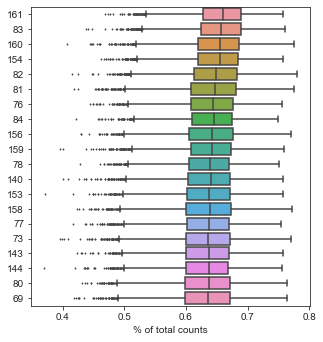

In [66]:
sc.pl.highest_expr_genes(adata, n_top=20, )

In [67]:
target_df

,9,25,33,35,40,41,44,46,55,63,...,934,943,945,964,965,992,993,997,allele,peptide
NTSDLYGLITEQFLC,-147.193668,-163.305762,-151.371017,-137.233587,-145.107597,-155.310360,-142.308141,-142.824449,-156.704099,-144.073965,...,-169.886013,-162.711247,-179.687117,-154.821320,-171.564198,-156.458056,-160.924948,-162.064775,HLA-DRB1*01:01,NTSDLYGLITEQFLC
IVQNAYKQMIKSRTL,-159.132260,-155.961868,-166.274980,-167.031485,-158.145561,-164.333283,-165.395621,-176.912305,-166.206609,-147.962082,...,-168.107937,-153.440048,-153.153694,-155.118990,-176.715590,-159.320895,-140.780715,-167.421010,HLA-DRB1*01:01,IVQNAYKQMIKSRTL
PGFIIMAAILAYTIG,-137.483194,-143.916015,-163.620373,-121.783361,-167.603706,-144.434366,-142.120890,-108.722812,-157.060424,-140.956320,...,-166.433038,-138.525240,-176.347964,-171.810386,-189.503072,-141.742199,-173.526427,-175.636457,HLA-DRB1*01:01,PGFIIMAAILAYTIG
VNTLHFLTRGKNIQL,-142.003772,-141.765985,-156.874363,-160.580961,-138.734733,-173.410788,-137.674472,-166.874149,-159.765686,-156.935601,...,-147.987506,-155.212262,-153.220122,-172.096721,-160.762982,-138.942734,-164.602980,-178.562569,HLA-DRB1*01:01,VNTLHFLTRGKNIQL
DRNAFVTGIARYIEQ,-163.264571,-154.784637,-132.031291,-132.593846,-141.081904,-157.145196,-163.729585,-118.909333,-155.540006,-150.988364,...,-168.152405,-185.933356,-152.314958,-181.949504,-155.855411,-141.517666,-162.064030,-160.702493,HLA-DRB1*01:01,DRNAFVTGIARYIEQ
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
QDRQGKTPLTLVDLC,-167.112503,-174.150071,-131.371691,-125.192638,-146.813671,-164.577578,-147.185917,-157.118273,-137.674099,-174.832263,...,-151.361690,-174.697363,-169.812931,-167.015970,-133.417911,-171.773758,-166.791483,-168.204637,HLA-DRB1*01:01,QDRQGKTPLTLVDLC
EAMSCDFNGGKISVQ,-119.543326,-150.325502,-150.469446,-156.518202,-126.515604,-146.966220,-144.465638,-162.652178,-176.510673,-127.345824,...,-168.771003,-155.170347,-152.680246,-160.786003,-135.163047,-170.067616,-171.115514,-170.316628,HLA-DRB1*01:01,EAMSCDFNGGKISVQ
FTKFHDELGDKFCYS,-146.528693,-157.873240,-147.170050,-173.431640,-114.648261,-165.593447,-129.455515,-136.075533,-158.484758,-130.091348,...,-168.409834,-174.796250,-173.078316,-169.412867,-163.083245,-176.492888,-174.085683,-177.632053,HLA-DRB1*01:01,FTKFHDELGDKFCYS
TGNLKFGLSYKEQVG,-149.737929,-135.860135,-124.816662,-141.125300,-148.622756,-145.958469,-150.152440,-155.884429,-184.237769,-141.803923,...,-138.023395,-150.715168,-157.535398,-150.242216,-160.142419,-159.544223,-170.731731,-159.371413,HLA-DRB1*01:01,TGNLKFGLSYKEQVG


## 1. Normalize

In [68]:
# sc.pp.scale(adata)

In [69]:
adata.X

array([[147.19366798, 163.30576165, 151.37101691, ..., 156.45805578,
        160.92494756, 162.06477455],
       [159.13225952, 155.96186842, 166.27497983, ..., 159.32089499,
        140.78071517, 167.42101007],
       [137.48319364, 143.91601526, 163.62037296, ..., 141.74219949,
        173.52642705, 175.63645731],
       ...,
       [146.52869315, 157.87323965, 147.17005027, ..., 176.49288822,
        174.08568319, 177.63205321],
       [149.73792923, 135.86013464, 124.81666231, ..., 159.54422281,
        170.73173125, 159.37141305],
       [133.82973672, 146.20276463, 159.88808291, ..., 164.69587474,
        162.73453911, 167.93840049]])

In [70]:
sc.pp.normalize_total(adata) # Total-count normalize (library-size correct) the data matrix X to 10,000 reads per cell, so that counts become comparable among cells.
sc.pp.log1p(adata) # log-normalization

In [71]:
adata.X

array([[4.99313087, 5.09633638, 5.02092832, ..., 5.05376783, 5.08174071,
        5.08875505],
       [5.06252807, 5.04253259, 5.10616338, ..., 5.06370527, 4.94082061,
        5.11299063],
       [4.92588876, 4.97129258, 5.09877621, ..., 4.95617893, 5.15720864,
        5.16922584],
       ...,
       [4.98829089, 5.06237206, 4.99262864, ..., 5.17319213, 5.15953751,
        5.1795895 ],
       [5.01853165, 4.92194635, 4.83781072, ..., 5.08155954, 5.14892488,
        5.08048254],
       [4.89364348, 4.98143515, 5.07032708, ..., 5.09977023, 5.08786341,
        5.11914914]])

## 2. Highly variable features

In [72]:
import matplotlib.pyplot as plt
# sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5)
# sc.pl.highly_variable_genes(adata, show=False) # can not scale only x

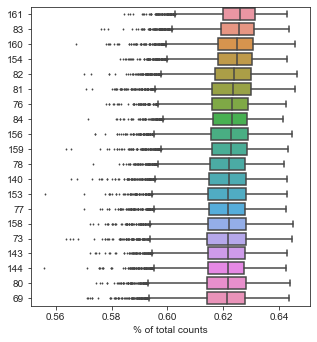

In [73]:
sc.pl.highest_expr_genes(adata, n_top=20, )

## 3. PCA

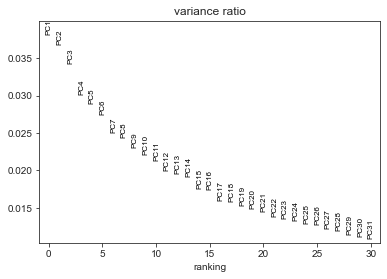

In [74]:
sc.tl.pca(adata, svd_solver='arpack')
sc.pl.pca_variance_ratio(adata)

## Regress out PC1

In [75]:
#not doing now
# adata.obsm['X_pca'][:, 0:1]  = 0
# adata.varm['PCs'][:, 0:1] = 0
# adata.uns['pca']['variance_ratio'][0:1] = 0
# adata.uns['pca']['variance'][0:1] = 0
# adata.obsm['X_pca']

In [282]:
# sc.pl.pca_variance_ratio(adata)

In [283]:
#Some plots for PCA distributions
#from itertools import product
#sc.pl.pca(adata, color='length',dimensions=list(product(range(5), repeat=2)), ncols=5 )
#sc.pl.pca(adata, color='length',dimensions=[(i,i) for i in range(20)], ncols=5 )

In [284]:
# import seaborn as sns
# n=10
# fig, axes = plt.subplots(nrows=n//5, ncols=5, figsize=(25, 5*n/5))

# for i,ax in enumerate(axes.flatten()):
#     df = pd.DataFrame({f"PC_{i}":adata.obsm['X_pca'][:,i], "length" : adata.obs['length'].values })
#     sns.histplot(df, x=f"PC_{i}", hue='length', ax=ax )

## 4. Neighborhood graph and umap

In [76]:
from itertools import product
import seaborn as sns
import matplotlib.pyplot as plt

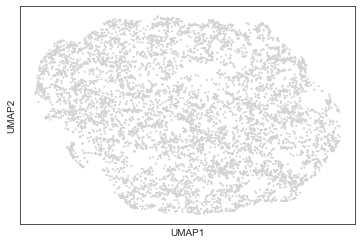

In [79]:
sc.pp.neighbors(adata, n_neighbors=25, n_pcs=5, metric="euclidean")
sc.tl.umap(adata, min_dist=0.01, n_components=2)
sc.pl.umap(adata)

## 5.  Cell clusters

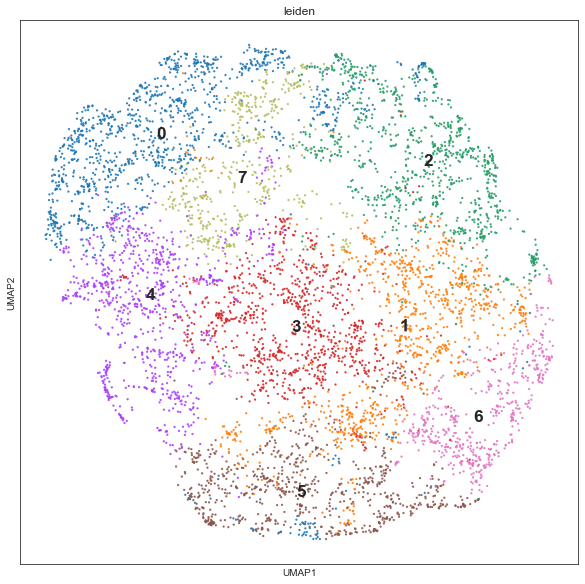

In [81]:
from matplotlib.pyplot import rc_context
with rc_context({'figure.figsize': (10, 10)}):
    sc.tl.leiden(adata, resolution=0.5)
    sc.tl.louvain(adata, resolution=0.3)
    sc.pl.umap(adata, color='leiden', s=20, 
               # add_outline=True, 
               legend_loc='on data',
              legend_fontsize='xx-large',
              legend_fontweight='bold', 
               alpha=0.9)
    # sc.pl.umap(adata, color='louvain', s=20)


<AxesSubplot:xlabel='0', ylabel='1'>

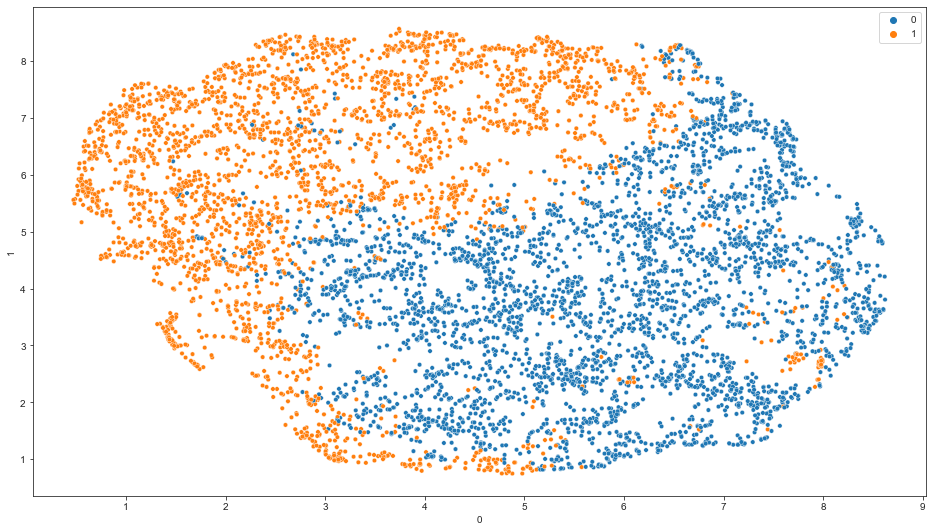

In [82]:
plt.figure(figsize=(16,9))
df = pd.DataFrame(adata.obsm['X_umap'])
sns.scatterplot(data=df, x=0, y=1,s=20, hue=adata.obs['louvain'].values)



## 6. Color by allele

In [83]:
adata_copy = adata_copy = adata[~adata.obs['allele'].str.contains('imm')]

D:\Tools\Python\Anaconda\envs\pomegranate\lib\site-packages\anndata\compat\_overloaded_dict.py:106: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  self.data[key] = value
D:\Tools\Python\Anaconda\envs\pomegranate\lib\contextlib.py:126: FutureWarning: X.dtype being converted to np.float32 from float64. In the next version of anndata (0.9) conversion will not be automatic. Pass dtype explicitly to avoid this warning. Pass `AnnData(X, dtype=X.dtype, ...)` to get the future behavour.
  next(self.gen)


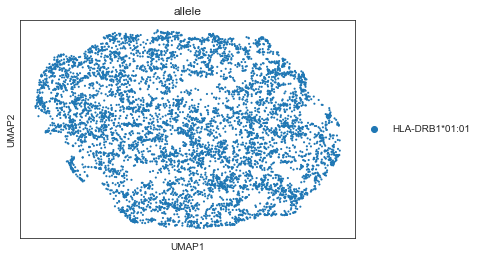

In [84]:
sc.pl.umap(adata_copy, color="allele")

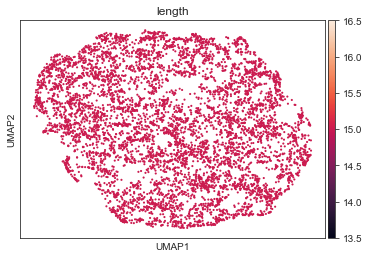

In [85]:
sc.pl.umap(adata_copy, color="length")

<AxesSubplot:xlabel='0', ylabel='1'>

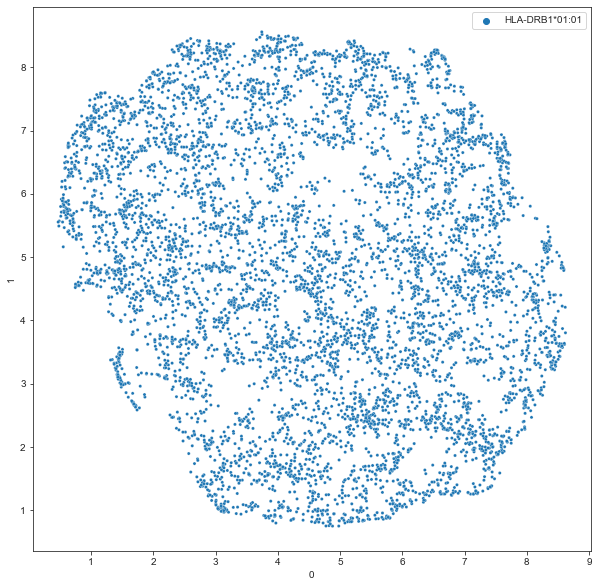

In [86]:
plt.figure(figsize=(10,10))
df = pd.DataFrame(adata_copy.obsm['X_umap'])
sns.scatterplot(data=df, x=0, y=1,s=10, hue=adata_copy.obs['allele'].values)

<AxesSubplot:xlabel='0', ylabel='1'>

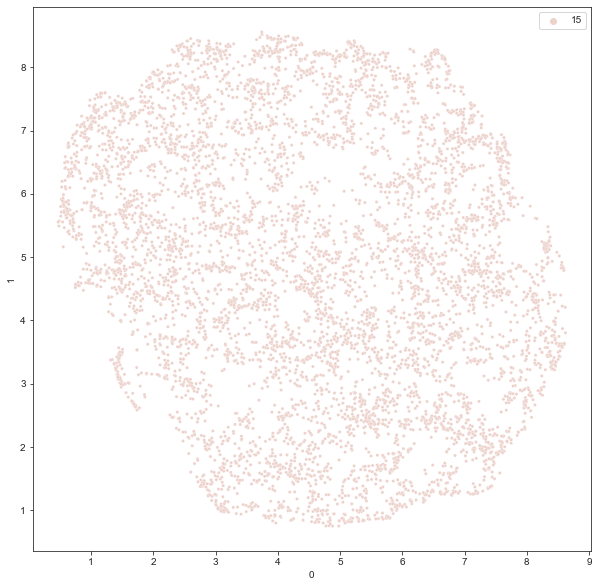

In [87]:
plt.figure(figsize=(10,10))
df = pd.DataFrame(adata_copy.obsm['X_umap'])
sns.scatterplot(data=df, x=0, y=1,s=10, hue=adata_copy.obs['length'].values)

## Color by immunogenicity

In [88]:
adata.obs['immunogenic'] = adata.obs['allele'].str.contains('imm').astype(int)
adata.obs

,peptide,allele,length,leiden,louvain,immunogenic
0,NTSDLYGLITEQFLC,HLA-DRB1*01:01,15,0,1,0
1,IVQNAYKQMIKSRTL,HLA-DRB1*01:01,15,3,0,0
2,PGFIIMAAILAYTIG,HLA-DRB1*01:01,15,5,0,0
3,VNTLHFLTRGKNIQL,HLA-DRB1*01:01,15,3,0,0
4,DRNAFVTGIARYIEQ,HLA-DRB1*01:01,15,2,1,0
...,...,...,...,...,...,...
6670,QDRQGKTPLTLVDLC,HLA-DRB1*01:01,15,5,0,0
6671,EAMSCDFNGGKISVQ,HLA-DRB1*01:01,15,2,0,0
6672,FTKFHDELGDKFCYS,HLA-DRB1*01:01,15,1,0,0
6673,TGNLKFGLSYKEQVG,HLA-DRB1*01:01,15,1,0,0


In [89]:
adata.obs['immunogenic']

0       0
1       0
2       0
3       0
4       0
       ..
6670    0
6671    0
6672    0
6673    0
6674    0
Name: immunogenic, Length: 6675, dtype: int32

<AxesSubplot:xlabel='0', ylabel='1'>

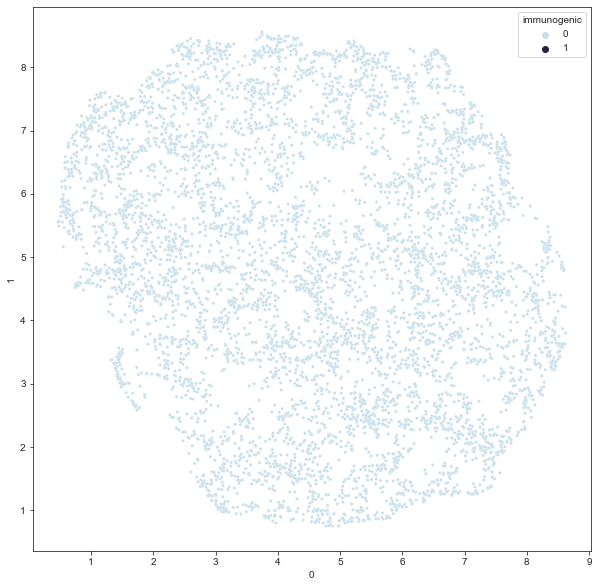

In [90]:
plt.figure(figsize=(10,10))
df = pd.DataFrame(adata.obsm['X_umap']).copy()
df['immunogenic'] = adata.obs['immunogenic'].values
colors = sns.color_palette("ch:s=.25,rot=-.25", 2)
hue_order = [0, 1]
sns.scatterplot(data=df.sort_values(by='immunogenic'), x=0, y=1,s=10, hue='immunogenic', palette=colors, hue_order=hue_order)

## 7. Plot cluster motifs

In [91]:
peptides_df = adata.obs.copy()

In [92]:
counts = dict(peptides_df['allele'].value_counts())
counts = dict(sorted(counts.items()))
# prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
b_counts = [(key,value) if not key.endswith('imm') else 0 for key,value in counts.items() ]
i_counts = [value if key.endswith('imm') else 0 for key,value in counts.items() ]
counts_str = "\n".join([f'{key}: B {b_value}, I {i_value}' for (key,b_value), i_value in zip(b_counts, i_counts)])


In [93]:
counts_str

'HLA-DRB1*01:01: B 6675, I 0'

In [94]:
import logomaker
def make_logo(df, length=9, cluster_num=0, ax=None, description_ax=None):
    filtered = df[df['length'] == length]
    if len(filtered) > 0:
        matrix = logomaker.alignment_to_matrix(filtered['peptide'].values)
        info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
        counts = dict(filtered['allele'].value_counts())
        counts = dict(sorted(counts.items()))
        # prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
        ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', ax=ax)
        b_counts = [(key,value) if not key.endswith('imm') else 0 for key,value in counts.items() ]
        i_counts = [value if key.endswith('imm') else 0 for key,value in counts.items() ]

        counts_str = "\n".join([f'{key}: B {b_value}, I {i_value}' for (key,b_value), i_value in zip(b_counts, i_counts)])
        # if description_ax is not None:
        #     description_ax.text(0.1, 0.1,f'Allele counts:\n {counts_str}', fontsize=9) #add text
        ww_logo.ax.set_title(f"Cluster {cluster_num} \n {counts_str}")

In [95]:
def plot_all_cluster_motifs(source_df, cluster_column = 'leiden', target_length=9 ):
    unique_clusters = peptides_df[cluster_column].unique()
    fig, axes = plt.subplots(nrows=len(unique_clusters), ncols=2, figsize=(9,2*len(unique_clusters)))
    for i, cluster_num in enumerate(unique_clusters):
        print(i)
        ax = axes[i, 0]
        df = source_df[source_df[cluster_column] == cluster_num]
        make_logo(df,length=target_length, cluster_num=cluster_num, ax=ax)
        # Additionaly plot immunogenic peptides
        ax = axes[i, 1]
        df = source_df[(source_df[cluster_column] == cluster_num) & (source_df['immunogenic'] == 1)]
        print(len(df))
        if len(df) > 0:
            make_logo(df,length=target_length, cluster_num=cluster_num, ax=ax)
            # Put the legend out of the figure
    plt.tight_layout()
    fig.savefig('temp.png', transparent=False)



In [ ]:
plot_all_cluster_motifs(peptides_df, 'leiden',9)

In [ ]:
plot_all_cluster_motifs(peptides_df, 'leiden', 10)

In [ ]:
plot_all_cluster_motifs(peptides_df, 'leiden', 11)

0
0
1
0
2
0
3
0
4
0
5
0
6
0
7
0


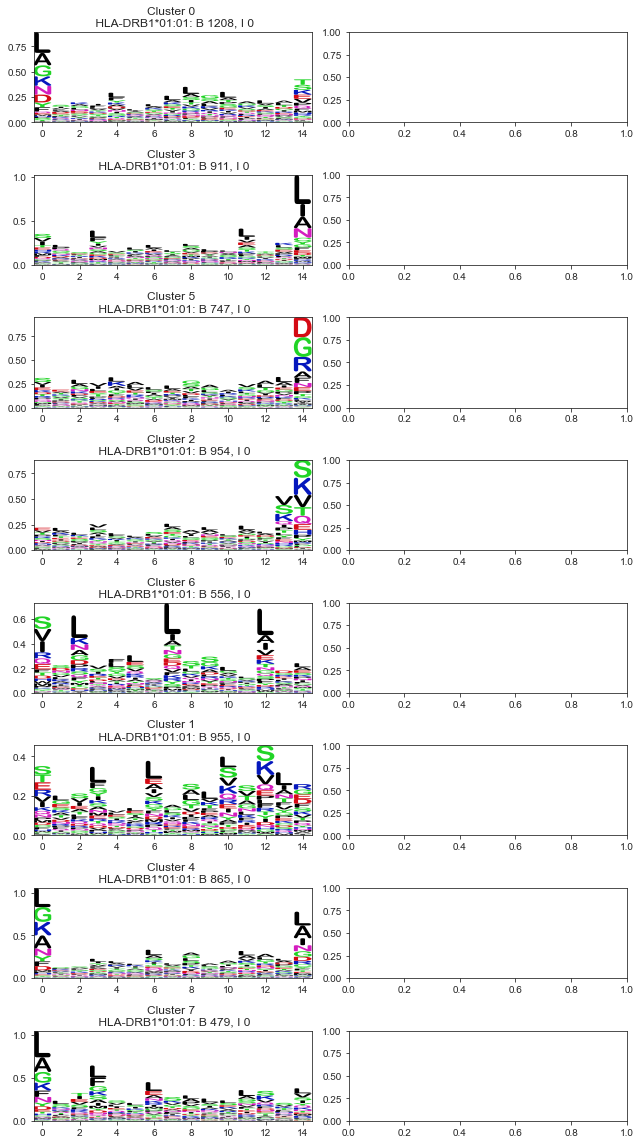

In [96]:
sns.set_style("ticks")
plot_all_cluster_motifs(peptides_df, 'leiden', 15)

In [326]:
matrix_df = target_df.drop(columns=['allele', 'peptide'])

D:\Tools\Python\Anaconda\envs\pomegranate\lib\site-packages\seaborn\matrix.py:654: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


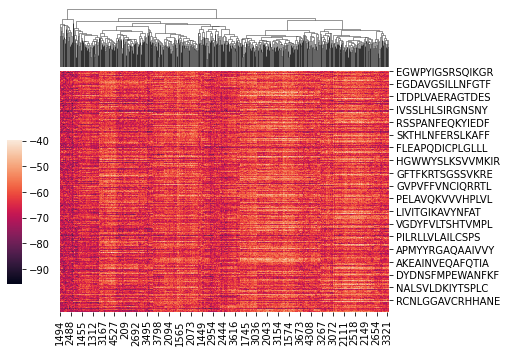

In [327]:
g = sns.clustermap(matrix_df,
                   figsize=(7, 5),
                   row_cluster=False,
                   dendrogram_ratio=(.1, .2),
                   cbar_pos=(0, .2, .03, .4))

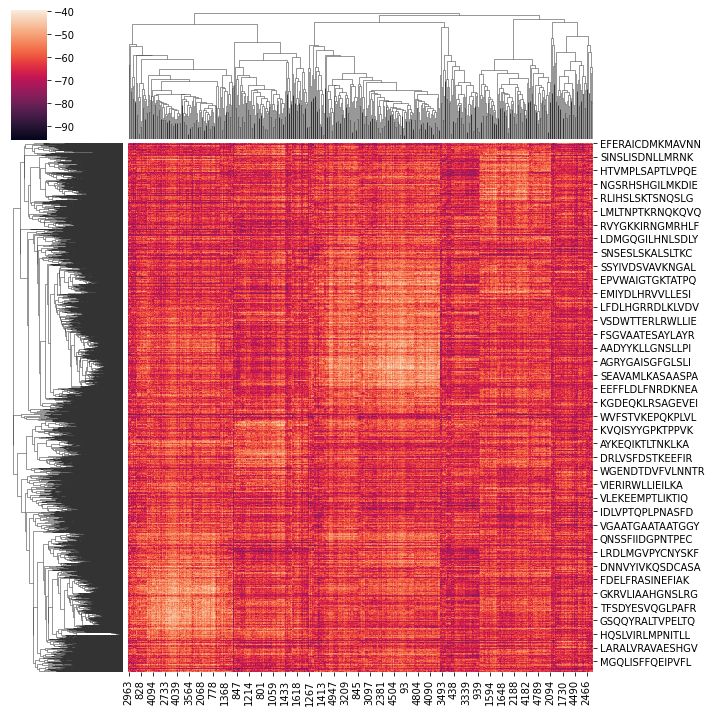

In [328]:
g = sns.clustermap(matrix_df, metric="correlation")

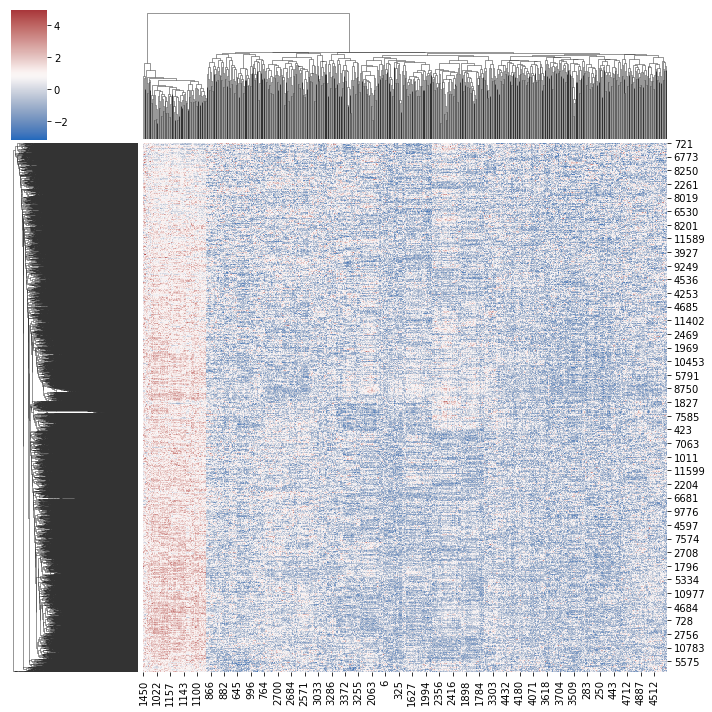

In [100]:
g = sns.clustermap(matrix_df, z_score=0, cmap="vlag")

In [253]:
indicies = g.dendrogram_col.reordered_ind

In [254]:
colums_to_check = list(indicies[0:5])

In [255]:
target_df.columns

Index(['0', '1', '2', '3', '7', '18', '40', '49', '59', '63',
       ...
       '4950', '4951', '4962', '4966', '4967', '4987', '4989', '4999',
       'allele', 'peptide'],
      dtype='object', length=838)

In [268]:
colums_to_check = list(target_df.columns[indicies[-5:]]) + ['peptide']

In [290]:
colums_to_check = ['4394','3775', '2388', '3810', 'peptide' ]

In [296]:
selected_col = '3810'
sorted_subset = target_df[colums_to_check].sort_values(by=selected_col, ascending=False)[:100]

Text(0.5, 1.0, 'path 3810')

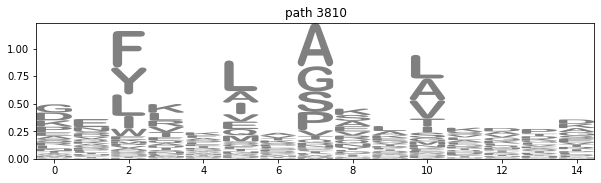

In [297]:
matrix = logomaker.alignment_to_matrix(sorted_subset['peptide'].values)
info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')      
ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold')
ww_logo.ax.set_title(f"path {selected_col}")

In [298]:
sorted_subset

,4394,3775,2388,3810,peptide
AEILELAGNAARDNK,-53.777150,-66.791633,-61.344496,-42.062483,AEILELAGNAARDNK
GRFERMLAAQGVDPG,-54.570452,-71.333968,-53.118183,-42.431745,GRFERMLAAQGVDPG
KNLLYLMPAKTVKPG,-54.251992,-67.421970,-41.183612,-42.676222,KNLLYLMPAKTVKPG
DPYEKIGAELVKEVA,-51.911862,-61.830179,-63.206672,-43.990073,DPYEKIGAELVKEVA
ENFEAAVGKLAKTPL,-61.926068,-68.108402,-62.138256,-44.093792,ENFEAAVGKLAKTPL
...,...,...,...,...,...
MDFKVIEGSFVYKGG,-58.541524,-63.634564,-65.428977,-49.081609,MDFKVIEGSFVYKGG
PYILLVSSKVSTVKD,-66.526278,-63.625840,-63.188373,-49.105929,PYILLVSSKVSTVKD
KALDFIASKGVKLVS,-54.964689,-47.338883,-63.326261,-49.148520,KALDFIASKGVKLVS
TDLQVLAARGAHVRQ,-57.955124,-49.607864,-62.856970,-49.165648,TDLQVLAARGAHVRQ


In [669]:
selected_peptides = peptides_df[~((peptides_df['leiden'] == '0') | (peptides_df['leiden'] == '8') )]

In [670]:
selected_peptides

,peptide,allele,length,leiden,louvain,immunogenic
0,AAMLDTVVFK,HLA-A*03:01,10,1,0,0
3,STGMYVANTK,HLA-A*03:01,10,1,0,0
4,PLHILASNKK,HLA-A*03:01,10,4,0,0
6,GSYDPQQIFK,HLA-A*03:01,10,1,0,0
8,RVGTVIGSNK,HLA-A*03:01,10,2,2,0
...,...,...,...,...,...,...
2157,LDLSLVTGLK,HLA-A*03:01,10,9,0,0
2158,FTDISMSLYK,HLA-A*03:01,10,6,0,0
2159,LSLSLVTGLK,HLA-A*03:01,10,9,0,0
2160,RVLDFDVKRK,HLA-A*03:01,10,2,2,0


## Hierarchical custering

In [329]:
df = target_df.copy()
X = df.drop(columns=['allele', 'peptide']).values
TOP = 2000
X = X.T[:TOP]
print(f"Shape of data {X.shape}")

Shape of data (694, 6675)


In [330]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import pairwise_distances
import scipy.cluster.hierarchy as sch
import matplotlib.pyplot as plt

[]

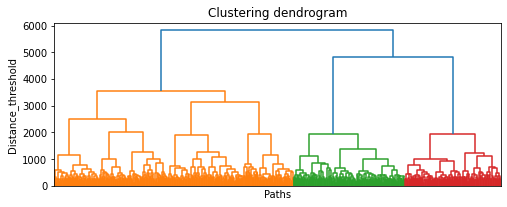

In [331]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(8, 3))
dendrogram = sch.dendrogram(sch.linkage(X, method='ward'), ax=ax)
ax.set_xlabel('Paths')
ax.set_ylabel('Distance_threshold')
ax.set_title(f"Clustering dendrogram")
ax.set_xticks([])

In [359]:
model = AgglomerativeClustering(
    n_clusters=None, linkage="ward", affinity='euclidean', distance_threshold=1700
)
model.fit(X)

AgglomerativeClustering(distance_threshold=1700, n_clusters=None)

In [360]:
unique_labels_counts = pd.Series(model.labels_).value_counts().sort_values(ascending=False)
path_to_label = {df.columns[i]:model.labels_[i] for i in range(X.shape[0])}
unique_labels_counts

0     113
7      88
3      82
5      70
1      63
2      61
8      60
4      55
6      43
10     36
9      23
dtype: int64

In [361]:
peptide_df = pd.DataFrame({"peptide": df.index.values, "allele": df['allele']})

In [362]:
peptide_df

,peptide,allele
EGWPYIGSRSQIKGR,EGWPYIGSRSQIKGR,HLA-DRB1*01:01
VGTIFIIQGLRSGGT,VGTIFIIQGLRSGGT,HLA-DRB1*01:01
ESNSEAIADKLDKSY,ESNSEAIADKLDKSY,HLA-DRB1*01:01
MANSRAFALVLLFCA,MANSRAFALVLLFCA,HLA-DRB1*01:01
PDDFMGCVLAWNTRN,PDDFMGCVLAWNTRN,HLA-DRB1*01:01
...,...,...
EGSFEDLTGNRVRYT,EGSFEDLTGNRVRYT,HLA-DRB1*01:01
RLKLFAAETLKATEE,RLKLFAAETLKATEE,HLA-DRB1*01:01
ADNFLLENTLPAQST,ADNFLLENTLPAQST,HLA-DRB1*01:01
QKLLKSIAATRGATV,QKLLKSIAATRGATV,HLA-DRB1*01:01


In [363]:
for label in unique_labels_counts.index:
    # peptide_df[f'path_gr_{label}'] = np.exp(df[ [path for path, cur_label in path_to_label.items() if cur_label == label]]).mean(axis=1).values
    peptide_df[f'path_gr_{label}'] = df[[path for path, cur_label in path_to_label.items() if cur_label == label]].max(axis=1).values


In [364]:
peptide_df['max_label'] = peptide_df[[f'path_gr_{label}' for label in path_to_label.values()]].idxmax(axis=1)
peptide_df['len'] = peptide_df['peptide'].str.len()
peptide_df

,peptide,allele,path_gr_0,path_gr_7,path_gr_3,path_gr_5,path_gr_1,path_gr_2,path_gr_8,path_gr_4,path_gr_6,path_gr_10,path_gr_9,max_label,len
EGWPYIGSRSQIKGR,EGWPYIGSRSQIKGR,HLA-DRB1*01:01,-56.754430,-52.212953,-58.942634,-55.487010,-53.987503,-54.876822,-56.393920,-65.585815,-58.287913,-58.021683,-64.443901,path_gr_7,15
VGTIFIIQGLRSGGT,VGTIFIIQGLRSGGT,HLA-DRB1*01:01,-47.245124,-50.562960,-55.651647,-55.238353,-57.635401,-53.152194,-51.105775,-54.259030,-57.658947,-56.884883,-63.526352,path_gr_0,15
ESNSEAIADKLDKSY,ESNSEAIADKLDKSY,HLA-DRB1*01:01,-53.828225,-55.818235,-59.570565,-52.286122,-55.842322,-56.184373,-54.663046,-57.624755,-58.594361,-55.532117,-62.579094,path_gr_5,15
MANSRAFALVLLFCA,MANSRAFALVLLFCA,HLA-DRB1*01:01,-54.292268,-56.807852,-57.001120,-51.861984,-56.330203,-57.445462,-56.382014,-57.782250,-61.525758,-56.179324,-63.358254,path_gr_5,15
PDDFMGCVLAWNTRN,PDDFMGCVLAWNTRN,HLA-DRB1*01:01,-60.584013,-57.429746,-65.181718,-64.177816,-63.677790,-57.271771,-59.731018,-62.988478,-56.513653,-64.541438,-61.323181,path_gr_6,15
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
EGSFEDLTGNRVRYT,EGSFEDLTGNRVRYT,HLA-DRB1*01:01,-42.641290,-55.457608,-60.726181,-60.340973,-51.015960,-54.669064,-47.505771,-56.093119,-54.152323,-58.641397,-60.118894,path_gr_0,15
RLKLFAAETLKATEE,RLKLFAAETLKATEE,HLA-DRB1*01:01,-47.082807,-47.505501,-57.178949,-52.058511,-54.903684,-51.674015,-52.281223,-54.337991,-49.785639,-58.242445,-52.775150,path_gr_0,15
ADNFLLENTLPAQST,ADNFLLENTLPAQST,HLA-DRB1*01:01,-44.099975,-52.373406,-52.993754,-49.806944,-55.444206,-52.984661,-47.685808,-54.301027,-52.616294,-51.475910,-60.823370,path_gr_0,15
QKLLKSIAATRGATV,QKLLKSIAATRGATV,HLA-DRB1*01:01,-46.002070,-51.919737,-57.145095,-49.027938,-48.673623,-54.288311,-49.240415,-52.510406,-54.806979,-55.863342,-59.280715,path_gr_0,15


In [365]:
peptide_df.max_label.value_counts()

path_gr_0     2234
path_gr_7     1600
path_gr_5     1192
path_gr_10     726
path_gr_6      242
path_gr_8      166
path_gr_4      151
path_gr_1      131
path_gr_2      118
path_gr_3      112
path_gr_9        3
Name: max_label, dtype: int64

In [366]:
peptide_df.groupby(['max_label','allele', 'len'])['peptide'].count()

max_label   allele          len
path_gr_0   HLA-DRB1*01:01  15     2234
path_gr_1   HLA-DRB1*01:01  15      131
path_gr_10  HLA-DRB1*01:01  15      726
path_gr_2   HLA-DRB1*01:01  15      118
path_gr_3   HLA-DRB1*01:01  15      112
path_gr_4   HLA-DRB1*01:01  15      151
path_gr_5   HLA-DRB1*01:01  15     1192
path_gr_6   HLA-DRB1*01:01  15      242
path_gr_7   HLA-DRB1*01:01  15     1600
path_gr_8   HLA-DRB1*01:01  15      166
path_gr_9   HLA-DRB1*01:01  15        3
Name: peptide, dtype: int64

In [367]:
TARGET_LENGTHS = [15]

0
1
2
3
4
5
6
7
8
9
10


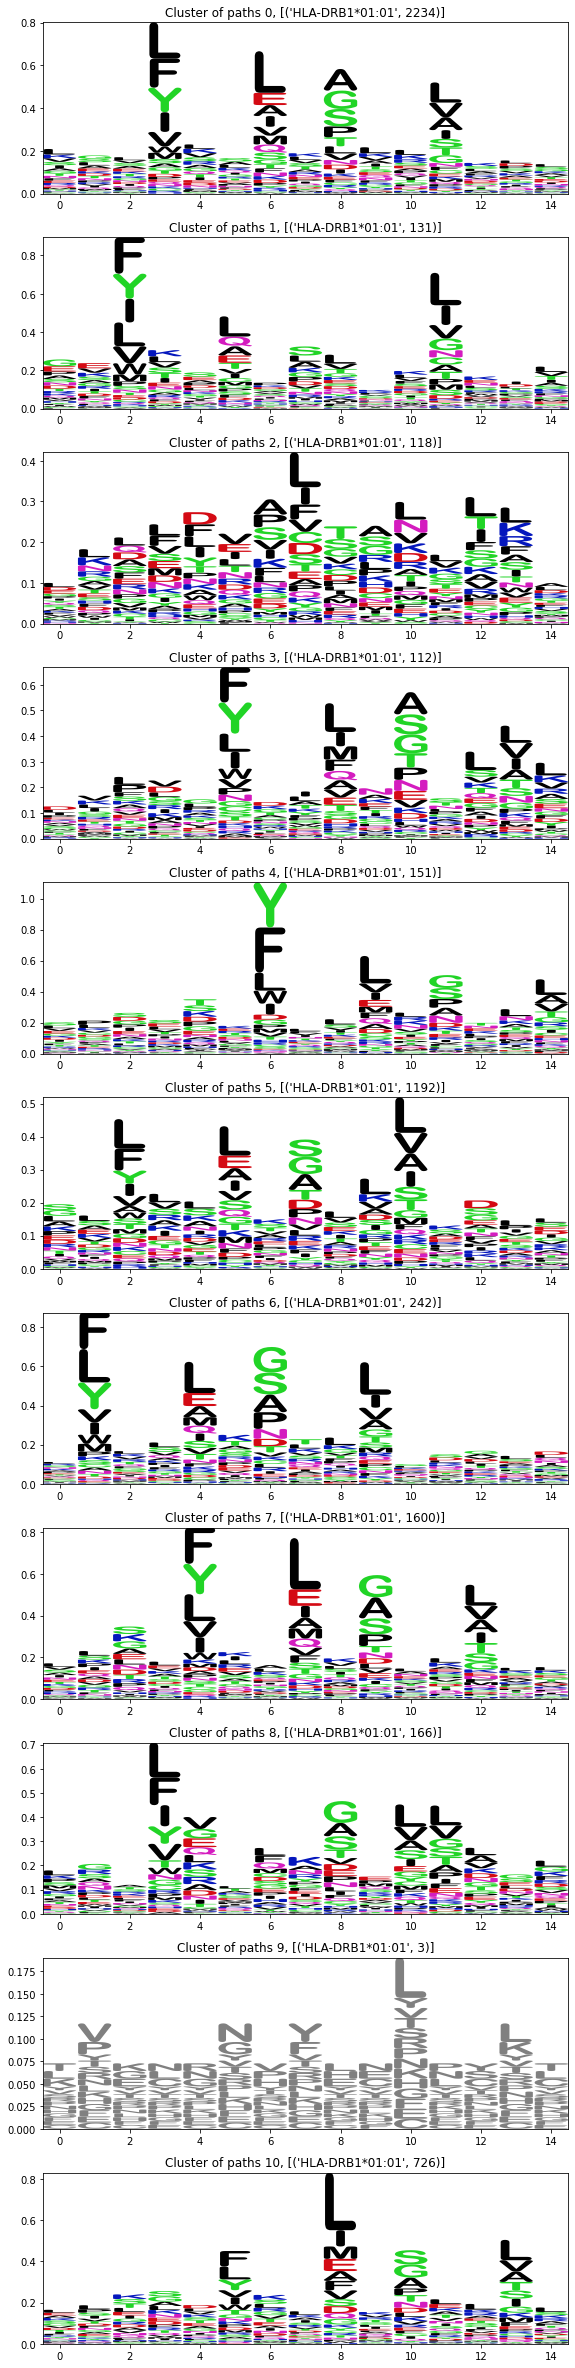

In [368]:

for target_length in TARGET_LENGTHS:
    fig, axes = plt.subplots(nrows=len(unique_labels_counts), figsize=(8, 3*len(unique_labels_counts)))
    for i, label in enumerate(sorted(unique_labels_counts.index)):
        target_label = f'path_gr_{label}'
        print(i)
        # filtered_df =  peptide_df.sort_values(by=f'path_gr_{label}', ascending=False)[:400]
        filtered_df =  peptide_df[peptide_df['max_label'] == target_label]
        filtered_df = filtered_df[filtered_df['len'] == target_length]
        # filtered_df =  filtered_df.sort_values(by=target_label, ascending=False)[:1000]
        counts = filtered_df['allele'].value_counts()


        matrix = logomaker.alignment_to_matrix(filtered_df['peptide'].values)
        info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
        # prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
        ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', ax=axes[i])
        # counts_list = [(key, value) for key, value in sorted(counts.items())]
        counts = [(key, value) for key, value in sorted(counts.items())]
        ww_logo.ax.set_title(f"Cluster of paths {label}, {counts}")
    plt.tight_layout()


## Motif in data

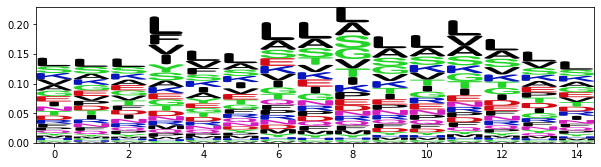

In [57]:
matrix = logomaker.alignment_to_matrix(peptides_df['peptide'].values)
info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')      
ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold')

kk cluster 2

In [43]:
analysis_df = peptides_df[(peptides_df['leiden'] == '2') & (peptides_df['length'] == 10)]

In [44]:
len(analysis_df)

53

In [45]:
analysis_df.head(30)

,peptide,allele,length,leiden,louvain,immunogenic
16,LLYQGVYLKK,HLA-A*03:01,10,2,2,0
141,SLIGYLITKK,HLA-A*03:01,10,2,2,0
378,ILARWSSFKK,HLA-A*03:01,10,2,2,0
628,FLAQALSPKL,HLA-A*03:01,10,2,2,0
909,RLVQGSILKK,HLA-A*03:01,10,2,2,0
1028,ILKRWGQLKK,HLA-A*03:01,10,2,2,0
1055,TLYISECLKK,HLA-A*03:01,10,2,2,0
1184,KLFDFVNAKK,HLA-A*03:01,10,2,2,0
1234,QLCYCPASKK,HLA-A*03:01,10,2,2,0
1235,FLILCFTIKR,HLA-A*03:01,10,2,1,0


In [46]:
analysis_df['peptide'].str.contains('KK$').value_counts()

True     31
False    22
Name: peptide, dtype: int64

In [47]:
analysis_df['peptide'].str.contains('K[^K]$').value_counts()

False    37
True     16
Name: peptide, dtype: int64

In [48]:
analysis_df['peptide'].str.contains('[^K]K$').value_counts()

False    47
True      6
Name: peptide, dtype: int64

kkcluster 1

In [49]:
analysis_df = peptides_df[(peptides_df['leiden'] == '1') & (peptides_df['length'] == 10)]

In [50]:
len(analysis_df)

94

In [51]:
analysis_df['peptide'].str.contains('KK$').value_counts()

False    54
True     40
Name: peptide, dtype: int64

In [52]:
analysis_df['peptide'].str.contains('K[^K]$').value_counts()

False    56
True     38
Name: peptide, dtype: int64

In [53]:
analysis_df['peptide'].str.contains('[^K]K$').value_counts()

False    89
True      5
Name: peptide, dtype: int64

In [62]:
analysis_df.iloc[75:100][['peptide', 'length']]

,peptide,length
5393,KLLDEAIQAV,10
5482,LALEVARQKR,10
5489,RVKLPSGSKK,10
5700,KTIDASVSKK,10
5773,VVLGNIIKKK,10
5922,FVFPLNSKVK,10
5948,KSFPGIPLHH,10
5969,SLRTACVPHR,10
6081,ISWEALRWKA,10
6163,AQYQFTGIKK,10


In [63]:
test_df = analysis_df[~((analysis_df['peptide'].str.contains('[^K]K$')) | 
                         (analysis_df['peptide'].str.contains('K[^K]$')) |
                          (analysis_df['peptide'].str.contains('KK$')))
                         ]

In [64]:
test_df               

,peptide,allele,length,leiden,louvain,immunogenic
167,KLFPGSPAIY,HLA-A*03:01,10,1,1,0
1744,KIDKLTFQIY,HLA-A*03:01,10,1,1,0
2544,KTKDPTAALR,HLA-A*03:01,10,1,0,0
3240,GLLDSIKMIY,HLA-A*03:01,10,1,1,0
3951,LTDFGLSKIM,HLA-A*03:01,10,1,1,0
4159,KLSYGIATVR,HLA-A*03:01,10,1,1,0
4661,ILDDNLYKVY,HLA-A*03:01,10,1,1,0
4945,VTLAILTALR,HLA-A*03:01,10,1,1,0
5393,KLLDEAIQAV,HLA-A*03:01,10,1,1,0
5948,KSFPGIPLHH,HLA-A*03:01,10,1,1,0


In [95]:
target_df.loc['RLNDRYPKKL'].drop(labels=['allele', 'peptide']).astype(float).sort_values(ascending=False).head(20)

98     -0.318822
101    -0.342753
354    -0.368054
2927   -0.383446
2648   -0.384295
0      -0.384449
393    -0.389404
27     -0.394635
151    -0.401635
218    -0.409427
742    -0.410926
390    -0.411313
2858   -0.415922
2667   -0.417967
164    -0.418814
160    -0.421213
3988   -0.429674
135    -0.432491
317    -0.433329
3099   -0.433387
Name: RLNDRYPKKL, dtype: float64

In [66]:
target_df.loc['FLAQALSPKL'][98]

-0.5738168380742605

In [67]:
#0-th model
filename = 'D:\\Projects\\MHC_predictor\\experiments\\length_dependent_hmm\\experiment_results\\alleles_with_groups_single_allele_balanced_data\\0_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_03_01-0\\viterbi_paths_df.csv'


In [68]:
df = pd.read_csv(filename, sep=';')

In [124]:
top500 = target_df.loc['RLNDRYPKKL'].drop(labels=['allele', 'peptide']).astype(float).sort_values(ascending=False).head(500).index

In [125]:
top500 = top500[top500.astype(int) < 500].astype(int)

In [126]:
top500

Int64Index([ 98, 101, 354,   0, 393,  27, 151, 218, 390, 164,
            ...
            406, 499, 105, 466, 385, 289, 439, 104, 492,  24],
           dtype='int64', length=143)

In [127]:
df

,path,prob,normalized_prob,len
0,grouped_model-start>s001>s004>s005>s008>s011>s...,-10.010188,-0.910017,9
1,grouped_model-start>s001>s004>s005>s014>s011>s...,-10.110780,-0.919162,9
2,grouped_model-start>s001>s003>s006>s008>s011>s...,-10.163696,-0.923972,9
3,grouped_model-start>s001>s004>s005>s007>s011>s...,-10.232188,-0.930199,9
4,grouped_model-start>s001>s004>s005>s007>s010>s...,-10.290974,-0.935543,9
...,...,...,...,...
708845,grouped_model-start>s003>s006>s014>s010>s014>s...,-32.849135,-2.986285,9
708846,grouped_model-start>s002>s007>s009>s014>s010>s...,-33.048400,-3.004400,9
708847,grouped_model-start>s002>s007>s014>s013>s011>s...,-33.216045,-3.019640,9
708848,grouped_model-start>s000>s008>s009>s006>s005>s...,-36.357856,-3.029821,10


In [129]:
df.loc[top500].len.value_counts()

9     126
10     17
Name: len, dtype: int64

In [76]:
df.loc[98]['path']

'grouped_model-start>s001>s004>s005>s008>s011>s010>s019>s015>s021>grouped_model-end'

In [79]:
df.loc[355]['path']

'grouped_model-start>s001>s004>s005>s014>s010>s012>s016>s019>s021>grouped_model-end'

In [80]:
df['path'][0]

'grouped_model-start>s001>s004>s005>s008>s011>s016>s019>s015>s021>grouped_model-end'

In [81]:
df['path'][:500].str.contains('s021>grouped_model-end').value_counts()

True    500
Name: path, dtype: int64

In [90]:
df['path'].str.contains('s021>grouped_model-end').value_counts()

False    496474
True     212376
Name: path, dtype: int64

In [86]:
df[:500]['len'].value_counts()

9     331
10    169
Name: len, dtype: int64

In [85]:
df.head(50)

,path,prob,normalized_prob,len
0,grouped_model-start>s001>s004>s005>s008>s011>s...,-10.010188,-0.910017,9
1,grouped_model-start>s001>s004>s005>s014>s011>s...,-10.110780,-0.919162,9
2,grouped_model-start>s001>s003>s006>s008>s011>s...,-10.163696,-0.923972,9
3,grouped_model-start>s001>s004>s005>s007>s011>s...,-10.232188,-0.930199,9
4,grouped_model-start>s001>s004>s005>s007>s010>s...,-10.290974,-0.935543,9
5,grouped_model-start>s001>s003>s009>s008>s011>s...,-10.295797,-0.935982,9
6,grouped_model-start>s001>s003>s006>s010>s019>s...,-10.385203,-0.944109,9
7,grouped_model-start>s001>s004>s006>s008>s011>s...,-10.401353,-0.945578,9
8,grouped_model-start>s001>s003>s006>s010>s012>s...,-10.419387,-0.947217,9
9,grouped_model-start>s001>s003>s006>s010>s016>s...,-11.375047,-0.947921,10


In [91]:
no_anchor_at_the_end = df[~df['path'].str.contains('s021>grouped_model-end')]

In [92]:
no_anchor_at_the_end

,path,prob,normalized_prob,len
770,grouped_model-start>s001>s004>s005>s008>s011>s...,-11.619110,-1.056283,9
972,grouped_model-start>s001>s004>s005>s014>s011>s...,-11.719701,-1.065427,9
1069,grouped_model-start>s001>s003>s006>s008>s011>s...,-11.772617,-1.070238,9
1258,grouped_model-start>s001>s004>s005>s007>s011>s...,-11.841109,-1.076464,9
1336,grouped_model-start>s001>s003>s008>s011>s016>s...,-12.953968,-1.079497,10
...,...,...,...,...
708845,grouped_model-start>s003>s006>s014>s010>s014>s...,-32.849135,-2.986285,9
708846,grouped_model-start>s002>s007>s009>s014>s010>s...,-33.048400,-3.004400,9
708847,grouped_model-start>s002>s007>s014>s013>s011>s...,-33.216045,-3.019640,9
708848,grouped_model-start>s000>s008>s009>s006>s005>s...,-36.357856,-3.029821,10


In [193]:
no_anchor_at_the_end.loc[770].path

'grouped_model-start>s001>s004>s005>s008>s011>s016>s019>s015>s024>grouped_model-end'

In [194]:
no_anchor_at_the_end.loc[972].path

'grouped_model-start>s001>s004>s005>s014>s011>s016>s019>s015>s024>grouped_model-end'

In [195]:
no_anchor_at_the_end.loc[1069].path

'grouped_model-start>s001>s003>s006>s008>s011>s016>s019>s015>s024>grouped_model-end'

In [93]:
no_anchor_at_the_end.loc[1258].path

'grouped_model-start>s001>s004>s005>s007>s011>s016>s019>s015>s024>grouped_model-end'

## Motif for 10 mers

In [247]:
df = peptides_df[peptides_df['length'] == 11]
make_logo(df,length=10, cluster_num=0)

In [310]:
peptides_df[peptides_df['peptide'].str.contains("K[^K]$")]

,peptide,allele,length,leiden,louvain,immunogenic
104,RLKGPLLNKR,HLA-A*03:01,10,5,2,0
122,KTSDVVLKR,HLA-A*03:01,9,3,0,0
139,LALEGSLQKR,HLA-A*03:01,10,1,1,0
178,IQNVPLSEKI,HLA-A*03:01,10,1,1,0
269,KSMRDQRKG,HLA-A*03:01,9,0,0,0
...,...,...,...,...,...,...
6113,TVYPVAIKY,HLA-A*03:01,9,0,0,0
6309,RIFVYFITKL,HLA-A*03:01,10,1,1,0
6313,KLYKNKSKQ,HLA-A*03:01,9,4,0,0
6475,VVFGILIKR,HLA-A*03:01,9,0,0,0


### Select metric

In [62]:
metrics = [  'sokalmichener', 'sokalsneath', 'yule', 'cosine', 'euclidean', 'l1', 'l2', 'manhattan','braycurtis', 'canberra', 'chebyshev', 'correlation', 'dice', 'hamming', 'jaccard', 'kulsinski', 'mahalanobis', 'minkowski', 'rogerstanimoto', 'russellrao']

metric: sokalmichener (0, 0)
metric: sokalsneath (0, 1)
metric: yule (0, 2)
metric: cosine (0, 3)
metric: euclidean (0, 4)
metric: l1 (1, 0)
metric: l2 (1, 1)
metric: manhattan (1, 2)
metric: braycurtis (1, 3)
metric: canberra (1, 4)
metric: chebyshev (2, 0)
metric: correlation (2, 1)
metric: dice (2, 2)
metric: hamming (2, 3)
metric: jaccard (2, 4)
metric: kulsinski (3, 0)
metric: mahalanobis (3, 1)


D:\Tools\Python\Anaconda\envs\pomegranate\lib\site-packages\pynndescent\pynndescent_.py:891: UserWarning: Failed to correctly find n_neighbors for some samples.Results may be less than ideal. Try re-running withdifferent parameters.
  warn(


metric: minkowski (3, 2)
metric: rogerstanimoto (3, 3)
metric: russellrao (3, 4)


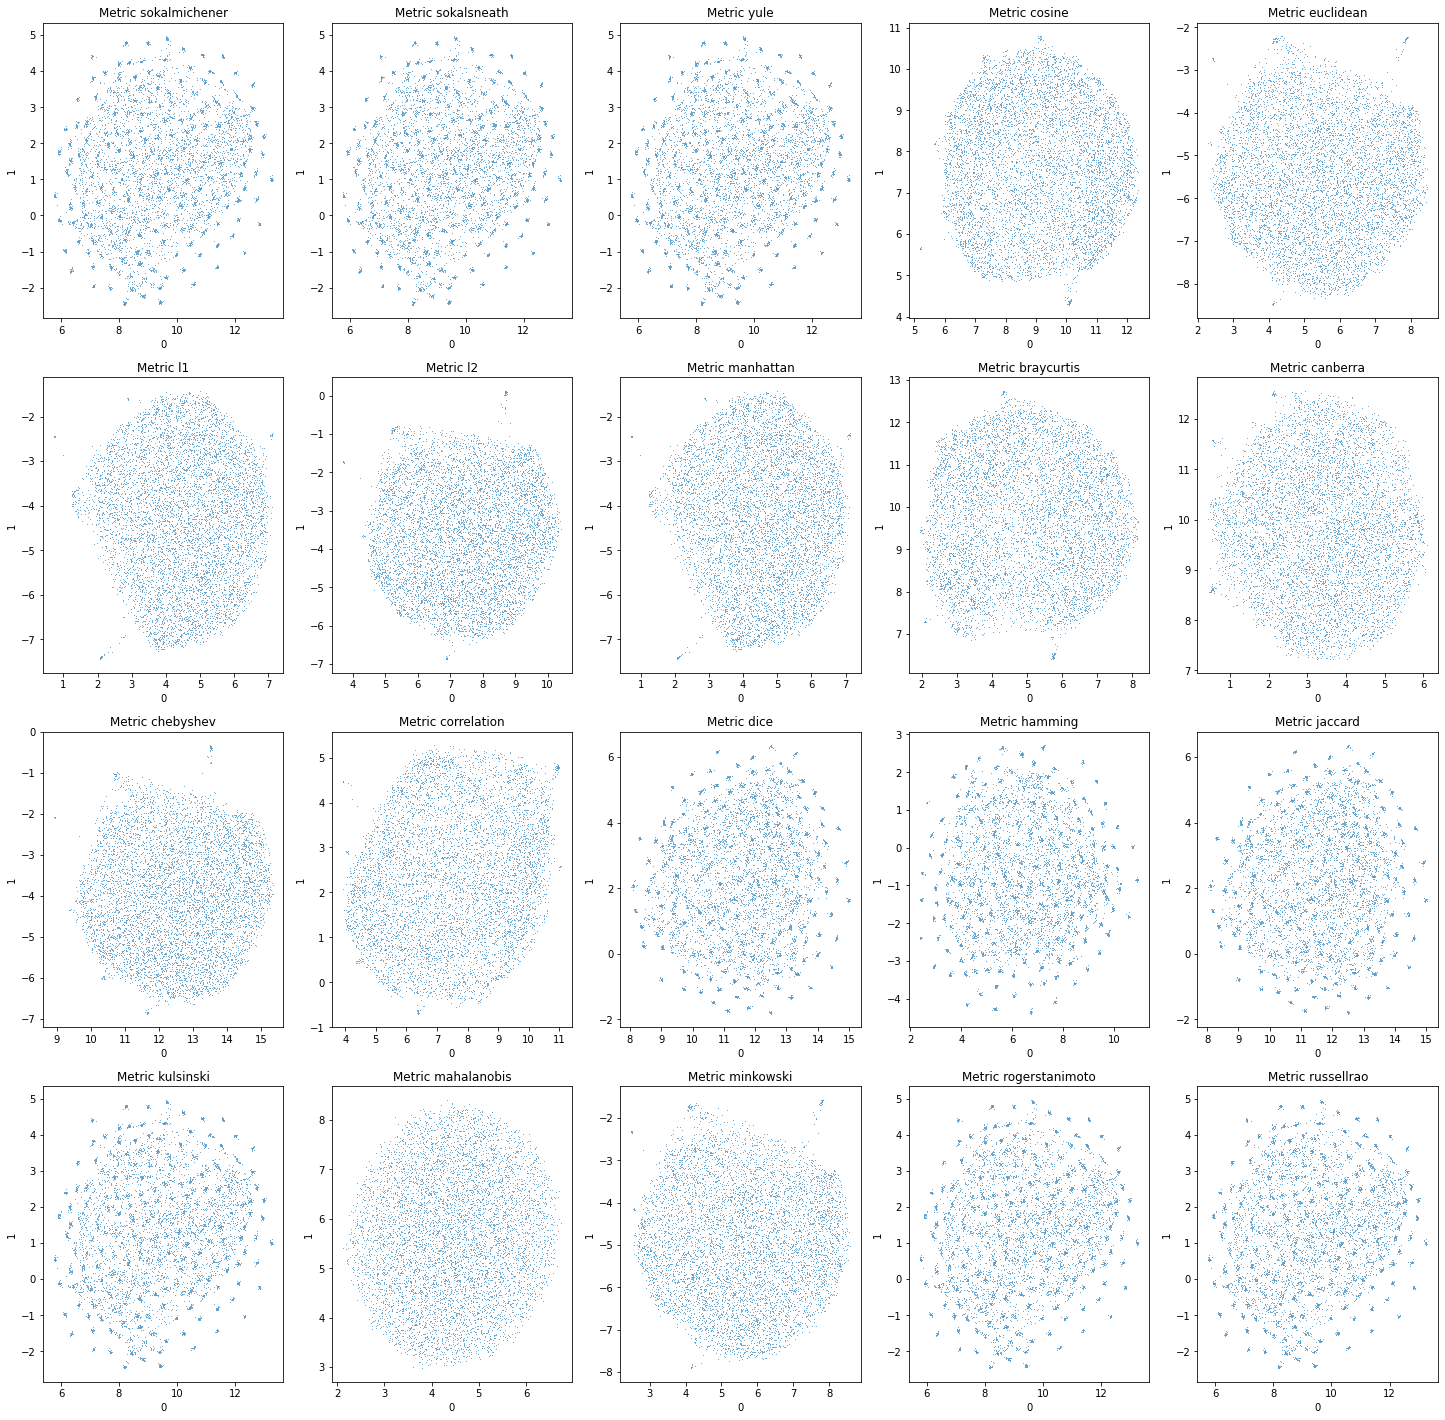

In [63]:
fig, axes = plt.subplots(nrows=4, ncols=5, figsize=(25,25))
for coord, metric in zip(product(range(5), range(5)), metrics):
    print("metric:", metric , coord)
    sc.pp.neighbors(adata, n_neighbors=30, n_pcs=20, metric=metric)
    sc.tl.umap(adata, min_dist=0.1)
    df = pd.DataFrame(adata.obsm['X_umap'])
    ax = axes[coord]
    sns.scatterplot(data=df, x=0, y=1, s=1, ax=ax)
    ax.set_title(f"Metric {metric}")

### Select number of principal components

In [120]:
principal_components = range(5, 30, 5)

In [121]:
list(principal_components)

[5, 10, 15, 20, 25]

In [122]:
len(list(principal_components))

5

n_pcs: 5
n_pcs: 10
n_pcs: 15
n_pcs: 20
n_pcs: 25


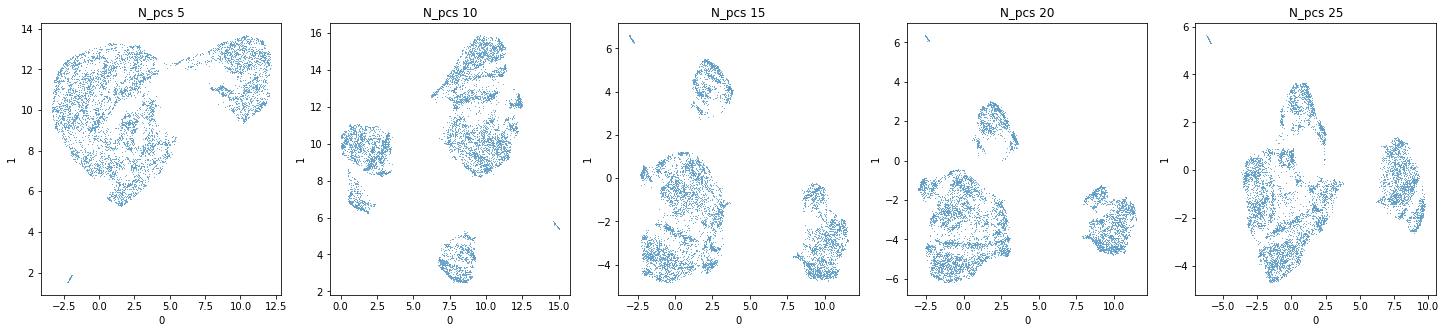

In [123]:
fig, axes = plt.subplots(ncols=5, figsize=(25,5))
for i, n_pcs in enumerate(principal_components):
    print("n_pcs:", n_pcs)
    sc.pp.neighbors(adata, n_neighbors=30, n_pcs=n_pcs, metric='euclidean')
    sc.tl.umap(adata, min_dist=0.1)
    df = pd.DataFrame(adata.obsm['X_umap'])
    ax = axes[i]
    sns.scatterplot(data=df, x=0, y=1, s=1, ax=ax)
    ax.set_title(f"N_pcs {n_pcs}")

### Select number of neighbours

In [59]:
num_neighbors = range(5, 55, 5)

In [60]:
len(num_neighbors)

10

n_neighbors: 5 (0, 0)
n_neighbors: 10 (0, 1)
n_neighbors: 15 (0, 2)
n_neighbors: 20 (0, 3)
n_neighbors: 25 (0, 4)
n_neighbors: 30 (1, 0)
n_neighbors: 35 (1, 1)
n_neighbors: 40 (1, 2)
n_neighbors: 45 (1, 3)
n_neighbors: 50 (1, 4)


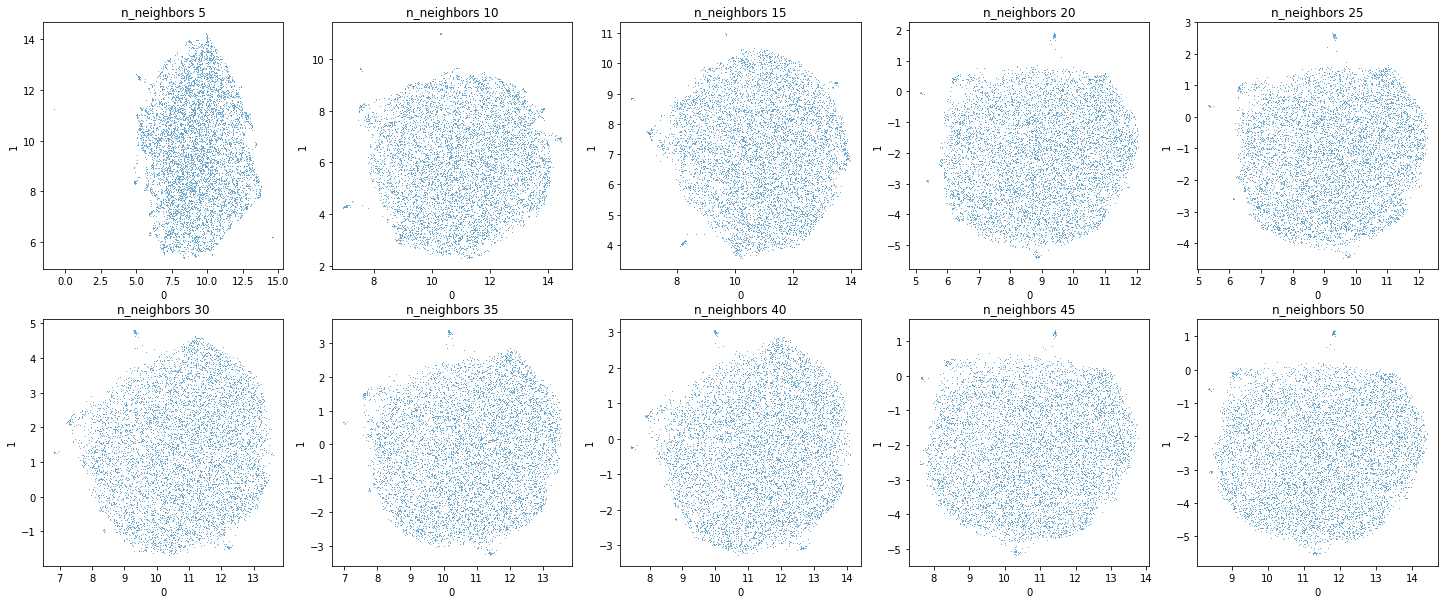

In [61]:
fig, axes = plt.subplots(ncols=5, nrows=2, figsize=(25,10))
for coord, n_neighbors in zip(product(range(2), range(5)), num_neighbors):
    print("n_neighbors:", n_neighbors , coord)
    sc.pp.neighbors(adata, n_neighbors=n_neighbors, n_pcs=15, metric='euclidean')
    sc.tl.umap(adata, min_dist=0.1)
    df = pd.DataFrame(adata.obsm['X_umap'])
    ax = axes[coord]
    sns.scatterplot(data=df, x=0, y=1, s=1, ax=ax)
    ax.set_title(f"n_neighbors {n_neighbors}")


### Select min_dist

In [159]:
min_dists = np.linspace(0.05, 0.5, 10)

min_dist: 0.05 (0, 0)
min_dist: 0.1 (0, 1)
min_dist: 0.15000000000000002 (0, 2)
min_dist: 0.2 (0, 3)
min_dist: 0.25 (0, 4)
min_dist: 0.3 (1, 0)
min_dist: 0.35000000000000003 (1, 1)
min_dist: 0.4 (1, 2)
min_dist: 0.45 (1, 3)
min_dist: 0.5 (1, 4)


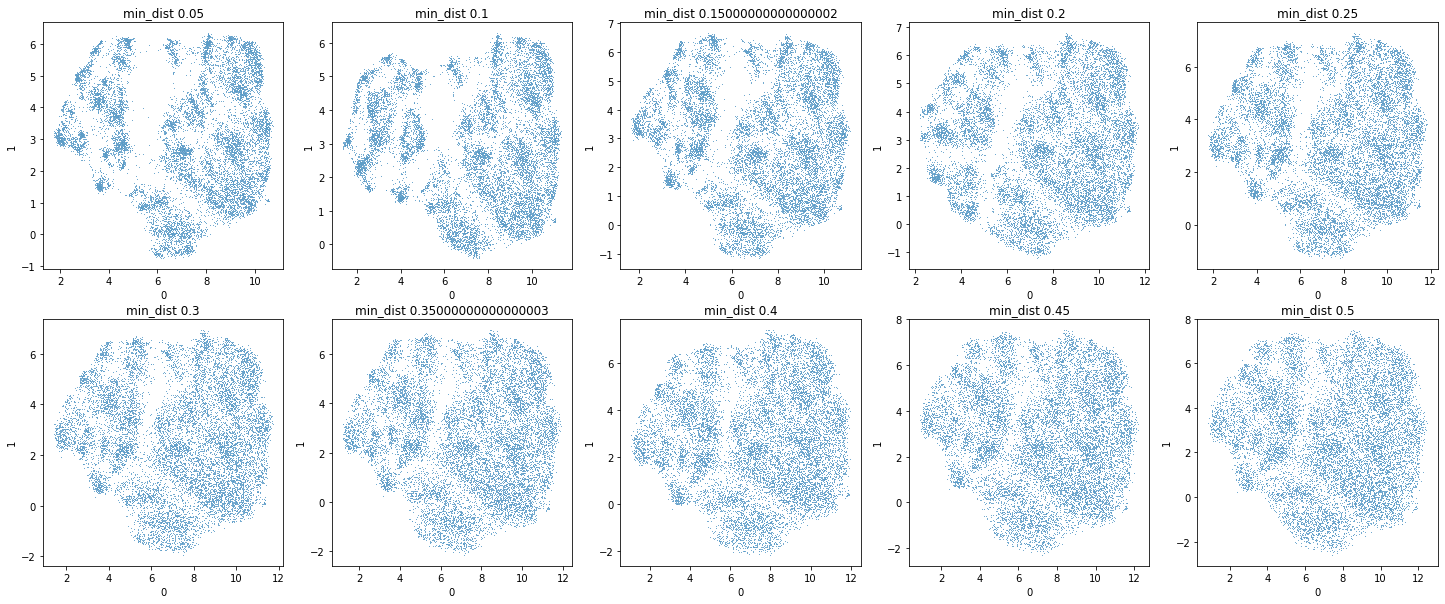

In [160]:
fig, axes = plt.subplots(ncols=5, nrows=2, figsize=(25,10))
for coord, min_dist in zip(product(range(2), range(5)), min_dists):
    print("min_dist:", min_dist , coord)
    sc.pp.neighbors(adata, n_neighbors=30, n_pcs=20, metric='euclidean')
    sc.tl.umap(adata, min_dist=min_dist)
    df = pd.DataFrame(adata.obsm['X_umap'])
    ax = axes[coord]
    sns.scatterplot(data=df, x=0, y=1, s=1, ax=ax)
    ax.set_title(f"min_dist {min_dist}")